# End-to-end Iris pipeline with simulated missing values

This is an educational classification exercise, not a business deployment. Iris
contains 150 flowers, four measurements and three species. Ten sepal-length
values (rows 0–9, all setosa) are deliberately replaced by NaN. This structured
simulation is not naturally occurring missingness and is not a general missing-data
model. Data is the offline scikit-learn copy of the UCI Iris dataset.

A stratified 80/20 split reserves 30 test rows (seed 42). Every training-fold fit
includes mean imputation, scaling, supervised L1 selection and KNN. Original
liblinear L1 selection is retained via explicit one-vs-rest binary fits, with
stacked coefficients for SelectFromModel; l1_ratio=1 uses the current sklearn API.
The original final grid search fitted the whole dataset; this version uses only
the 120 training rows. Test results appear only after model selection.

In [1]:
import json
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import sklearn
from sklearn.base import clone
from sklearn.datasets import load_iris
from sklearn.dummy import DummyClassifier
from sklearn.feature_selection import SelectFromModel
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (accuracy_score, balanced_accuracy_score, classification_report,
                             confusion_matrix, ConfusionMatrixDisplay, f1_score)
from sklearn.model_selection import GridSearchCV, StratifiedKFold, cross_validate, train_test_split
from sklearn.multiclass import OneVsRestClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler

print('scikit-learn:', sklearn.__version__, 'NumPy:', np.__version__)
iris = load_iris()
X, y = iris.data.copy(), iris.target
X[:10, 0] = np.nan
train_indices, test_indices = train_test_split(
    np.arange(len(y)), test_size=0.2, stratify=y, random_state=42,
)
X_train, X_test = X[train_indices], X[test_indices]
y_train, y_test = y[train_indices], y[test_indices]
assert set(train_indices).isdisjoint(test_indices)
assert len(X_train) == 120 and len(X_test) == 30
assert np.isnan(X).sum() == 10
print('Features:', iris.feature_names)
print('Training/test rows:', len(X_train), len(X_test))
print('Simulated missing entries in training/test:', np.isnan(X_train).sum(), np.isnan(X_test).sum())

scikit-learn: 1.9.1 NumPy: 2.5.4
Features: ['sepal length (cm)', 'sepal width (cm)', 'petal length (cm)', 'petal width (cm)']
Training/test rows: 120 30
Simulated missing entries in training/test: 9 1


## Pipeline and training-only feasibility checks
At very small C, L1 may remove every feature. Check the original candidate grid
(0.01, 0.1, 1, 10) on training folds only, excluding any C that selects zero
features in a fold. This is a feasibility check, not evaluation on the test set.
Remaining candidates and KNN k=3,5,7 are searched on the same five stratified,
shuffled folds (seed 42). Grid-search errors are raised, not silently suppressed.

In [2]:
def ovr_coefficients(estimator):
    return np.vstack([binary_model.coef_[0] for binary_model in estimator.estimators_])


pipeline = Pipeline([
    ('imputer', SimpleImputer(strategy='mean')),
    ('scaler', StandardScaler()),
    ('feature_selection', SelectFromModel(
        OneVsRestClassifier(LogisticRegression(
            solver='liblinear', l1_ratio=1.0, C=1.0, random_state=42, max_iter=2000,
        )), importance_getter=ovr_coefficients, threshold=1e-5,
    )),
    ('classifier', KNeighborsClassifier(n_neighbors=3)),
])
folds = list(StratifiedKFold(5, shuffle=True, random_state=42).split(X_train, y_train))
c_key = 'feature_selection__estimator__estimator__C'
candidate_checks = []
valid_c = []
for candidate in [0.01, 0.1, 1.0, 10.0]:
    selected_counts = []
    for fit_rows, validation_rows in folds:
        prefix = clone(pipeline[:-1]).set_params(**{c_key: candidate})
        prefix.fit(X_train[fit_rows], y_train[fit_rows])
        selected_counts.append(int(prefix.named_steps['feature_selection'].get_support().sum()))
    valid = min(selected_counts) > 0
    candidate_checks.append({'C': candidate, 'selected_features_per_fold': selected_counts, 'valid': valid})
    if valid:
        valid_c.append(candidate)
assert valid_c, 'No candidate retained any features in every training fold.'
print(pd.DataFrame(candidate_checks).to_string(index=False))

grid_search = GridSearchCV(
    pipeline, {c_key: valid_c, 'classifier__n_neighbors': [3, 5, 7]},
    cv=folds, scoring='accuracy', error_score='raise', n_jobs=1,
)
grid_search.fit(X_train, y_train)
print('Best parameters:', grid_search.best_params_)
print('Training selection CV accuracy:', grid_search.best_score_)

    C selected_features_per_fold  valid
 0.01            [0, 0, 0, 0, 0]  False
 0.10            [3, 3, 4, 3, 3]   True
 1.00            [3, 3, 4, 4, 3]   True
10.00            [4, 4, 4, 4, 4]   True


Best parameters: {'classifier__n_neighbors': 3, 'feature_selection__estimator__estimator__C': 0.1}
Training selection CV accuracy: 0.9666666666666668


## Check fitting boundaries and compare fixed baselines
Assertions inspect actual fitted fold estimators. Their imputer statistics must
equal the corresponding fold's means; scaler sample counts and means must match
only that fold's imputed training rows. The refitted selected model must have
seen exactly 120 training rows. No preprocessing fits the held-out test rows.

Fixed most-frequent-class and imputed/scaled KNN (k=3, no selection) baselines use
the same five training folds. The tuned model's best CV score is marked as a
selection score; it is optimistic after searching and is not an independent
performance estimate. Fold standard deviations are not confidence intervals.

In [3]:
audit = cross_validate(pipeline, X_train, y_train, cv=folds, scoring='accuracy',
                       return_estimator=True, error_score='raise')
for (fit_rows, validation_rows), fitted in zip(folds, audit['estimator']):
    assert set(fit_rows).isdisjoint(validation_rows)
    imputer = fitted.named_steps['imputer']
    scaler = fitted.named_steps['scaler']
    np.testing.assert_allclose(imputer.statistics_, np.nanmean(X_train[fit_rows], axis=0))
    np.testing.assert_allclose(scaler.mean_, imputer.transform(X_train[fit_rows]).mean(axis=0))
    assert scaler.n_samples_seen_ == len(fit_rows)

best_model = grid_search.best_estimator_
np.testing.assert_allclose(best_model.named_steps['imputer'].statistics_, np.nanmean(X_train, axis=0))
assert best_model.named_steps['scaler'].n_samples_seen_ == len(X_train)
print('Training-fold preprocessing and final-refit boundary assertions passed.')

baselines = {
    'Most frequent class': Pipeline([('imputer', SimpleImputer()), ('classifier', DummyClassifier(strategy='most_frequent'))]),
    'KNN (k=3, no selection)': Pipeline([('imputer', SimpleImputer()), ('scaler', StandardScaler()),
                                       ('classifier', KNeighborsClassifier(n_neighbors=3))]),
}
cv_records = {}
for name, model in baselines.items():
    scores = cross_validate(model, X_train, y_train, cv=folds, scoring='accuracy', error_score='raise')['test_score']
    model.fit(X_train, y_train)
    cv_records[name] = {'role': 'fixed baseline CV', 'mean': float(scores.mean()), 'std': float(scores.std())}
index = grid_search.best_index_
cv_records['Tuned L1 + KNN'] = {
    'role': 'hyperparameter selection CV', 'mean': float(grid_search.best_score_),
    'std': float(grid_search.cv_results_['std_test_score'][index]),
}

Training-fold preprocessing and final-refit boundary assertions passed.


## Final held-out evaluation (30 rows)
Model selection is complete. Evaluate the predefined baselines and selected model
on the same test rows using accuracy, balanced accuracy, macro F1 and classwise
precision/recall/F1. Report the confusion matrix rather than claiming an accuracy
alone establishes reliability. No result below changes the parameter search.

                  model  accuracy  balanced_accuracy  macro_f1
    Most frequent class  0.333333           0.333333  0.166667
KNN (k=3, no selection)  0.933333           0.933333  0.932660
         Tuned L1 + KNN  0.933333           0.933333  0.933333
Selected features: ['sepal width (cm)', 'petal length (cm)', 'petal width (cm)']


              precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        10
  versicolor       0.90      0.90      0.90        10
   virginica       0.90      0.90      0.90        10

    accuracy                           0.93        30
   macro avg       0.93      0.93      0.93        30
weighted avg       0.93      0.93      0.93        30



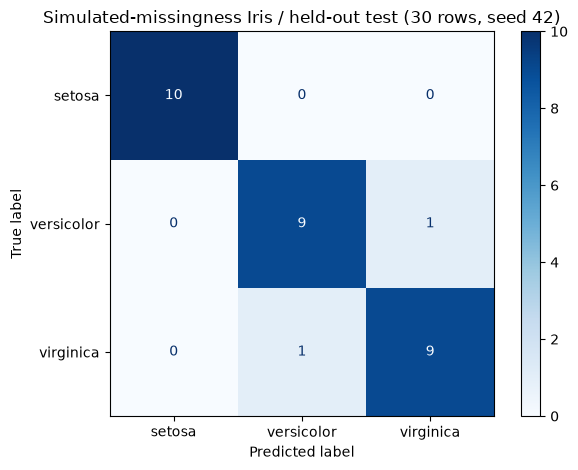

In [4]:
models = {**baselines, 'Tuned L1 + KNN': best_model}
records = []
for name, model in models.items():
    predictions = model.predict(X_test)
    records.append({
        'model': name, 'cv': cv_records[name],
        'accuracy': float(accuracy_score(y_test, predictions)),
        'balanced_accuracy': float(balanced_accuracy_score(y_test, predictions)),
        'macro_f1': float(f1_score(y_test, predictions, average='macro', zero_division=0)),
        'confusion_matrix': confusion_matrix(y_test, predictions, labels=[0, 1, 2]).tolist(),
        'classification_report': classification_report(
            y_test, predictions, labels=[0, 1, 2], target_names=iris.target_names,
            output_dict=True, zero_division=0,
        ),
    })
selected_features = np.asarray(iris.feature_names)[best_model.named_steps['feature_selection'].get_support()].tolist()
summary = {
    'dataset': 'UCI Iris via sklearn.datasets.load_iris', 'seed': 42,
    'train_samples': len(X_train), 'test_samples': len(X_test), 'folds': 5,
    'simulated_missingness': {'rows': '0-9', 'feature': iris.feature_names[0], 'entries': 10},
    'feature_names': iris.feature_names, 'candidate_feasibility': candidate_checks,
    'best_params': grid_search.best_params_, 'selected_features': selected_features,
    'fitting_boundary_checks': 'passed for every fold and the final training refit',
    'models': records,
}
Path('results.json').write_text(json.dumps(summary, indent=2) + '\n', encoding='utf-8')
print(pd.DataFrame([{key: row[key] for key in ['model', 'accuracy', 'balanced_accuracy', 'macro_f1']}
                    for row in records]).to_string(index=False))
print('Selected features:', selected_features)
print(classification_report(y_test, best_model.predict(X_test), target_names=iris.target_names, zero_division=0))
ConfusionMatrixDisplay.from_predictions(y_test, best_model.predict(X_test), display_labels=iris.target_names, cmap='Blues')
plt.title('Simulated-missingness Iris / held-out test (30 rows, seed 42)')
plt.tight_layout()
plt.show()

## Limits
The dataset is small and the missingness is deliberately concentrated in one
class. These scores describe one split; they do not establish real-world or
business performance. No model is deployed, persisted or monitored by this lab.
Legacy coursework notebooks are indexed in README but have not all been rerun
with this environment. The neural-network notebook needs separate TensorFlow
dependencies and its filename does not establish a measured 93% result.